# Supermarket Sales Analysis

## AICTE | IBM SkillsBuild Data Analytics with AI Internship 2026

### Project Overview

This project analyzes 500 supermarket sales transactions to identify
sales patterns, customer behavior, payment preferences, product
performance, category performance, branch performance, and customer
ratings.

### Author

**Kalia Sahu**

B.Tech - Computer Science and Engineering (IoT)

**Institute:** Institute of Technical Education and Research (ITER), SOA University

In [8]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.2f}")

print("Libraries imported successfully.")

Libraries imported successfully.


In [9]:
# Load the supermarket sales dataset

file_path = "data/supermarket_sales.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print(f"Rows    : {df.shape[0]}")
print(f"Columns : {df.shape[1]}")

Dataset loaded successfully.
Rows    : 500
Columns : 11


In [10]:
# Preview the dataset

print("First 5 rows:")
display(df.head())

First 5 rows:


,Transaction ID,Product,Category,Branch,City,Customer Type,Quantity,Unit Price,Payment Method,Rating,Sales
0,1,Cheese,Dairy,A,Bangalore,Normal,1,132.97,UPI,5.00,132.97
1,2,Cheese,Dairy,A,Bangalore,Member,1,186.11,UPI,5.00,186.11
2,3,Cheese,Dairy,B,Delhi,Member,1,195.23,UPI,5.00,195.23
3,4,Cheese,Dairy,A,Bangalore,Member,1,509.06,UPI,5.00,509.06
4,5,Cheese,Dairy,B,Delhi,Normal,1,97.78,UPI,5.00,97.78


In [11]:
# Dataset structure and column information

print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape:
(500, 11)

Column Names:
['Transaction ID', 'Product', 'Category', 'Branch', 'City', 'Customer Type', 'Quantity', 'Unit Price', 'Payment Method', 'Rating', 'Sales']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Transaction ID  500 non-null    int64  
 1   Product         500 non-null    str    
 2   Category        500 non-null    str    
 3   Branch          500 non-null    str    
 4   City            500 non-null    str    
 5   Customer Type   500 non-null    str    
 6   Quantity        500 non-null    int64  
 7   Unit Price      500 non-null    float64
 8   Payment Method  500 non-null    str    
 9   Rating          500 non-null    float64
 10  Sales           500 non-null    float64
dtypes: float64(3), int64(2), str(6)
memory usage: 43.1 KB


In [12]:
# Statistical summary

print("Statistical Summary:")
display(df.describe())

Statistical Summary:


,Transaction ID,Quantity,Unit Price,Rating,Sales
count,500.00,500.00,500.00,500.00,500.00
mean,250.50,1.00,488.71,3.99,488.71
std,144.48,0.00,248.34,1.00,248.34
min,1.00,1.00,83.73,3.00,83.73
25%,125.75,1.00,284.55,3.00,284.55
50%,250.50,1.00,477.18,3.00,477.18
75%,375.25,1.00,689.62,5.00,689.62
max,500.00,1.00,1110.48,5.00,1110.48


In [13]:
# Check for missing values

print("Missing Values:")
display(df.isnull().sum())

Missing Values:


Transaction ID    0
Product           0
Category          0
Branch            0
City              0
Customer Type     0
Quantity          0
Unit Price        0
Payment Method    0
Rating            0
Sales             0
dtype: int64

In [14]:
# Check for duplicate rows

duplicate_count = df.duplicated().sum()

print("Duplicate Rows:", duplicate_count)

Duplicate Rows: 0


In [15]:
# Verify the Sales calculation

df["Calculated Sales"] = df["Quantity"] * df["Unit Price"]

sales_check = np.isclose(
    df["Sales"],
    df["Calculated Sales"],
    atol=0.01
)

print("Sales calculation correct:", sales_check.all())

Sales calculation correct: True


In [16]:
df.drop(columns=["Calculated Sales"], inplace=True)

In [17]:
# Basic sales information

total_sales = df["Sales"].sum()
total_transactions = df["Transaction ID"].nunique()
total_quantity = df["Quantity"].sum()
average_sale = df["Sales"].mean()
average_rating = df["Rating"].mean()

print("=" * 50)
print("BASIC SALES INFORMATION")
print("=" * 50)

print(f"Total Sales        : Rs. {total_sales:,.2f}")
print(f"Total Transactions : {total_transactions}")
print(f"Total Quantity     : {total_quantity}")
print(f"Average Sale       : Rs. {average_sale:,.2f}")
print(f"Average Rating     : {average_rating:.2f} / 5")

BASIC SALES INFORMATION
Total Sales        : Rs. 244,356.00
Total Transactions : 500
Total Quantity     : 500
Average Sale       : Rs. 488.71
Average Rating     : 3.99 / 5


In [18]:
# Product sales analysis

product_sales = (
    df.groupby("Product")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print("Sales by Product:")
display(product_sales.to_frame(name="Total Sales"))

highest_product = product_sales.idxmax()
highest_product_sales = product_sales.max()

print(f"\nHighest Sales Product: {highest_product}")
print(f"Sales: Rs. {highest_product_sales:,.2f}")

Sales by Product:


,Total Sales
Product,
Cheese,27906.30
Chips,18959.68
Soft Drink,18813.69
Chocolate,18545.65
Shampoo,17952.66
Noodles,17351.48
Soap,16754.22
Pasta,16218.53
Rice,15044.32



Highest Sales Product: Cheese
Sales: Rs. 27,906.30


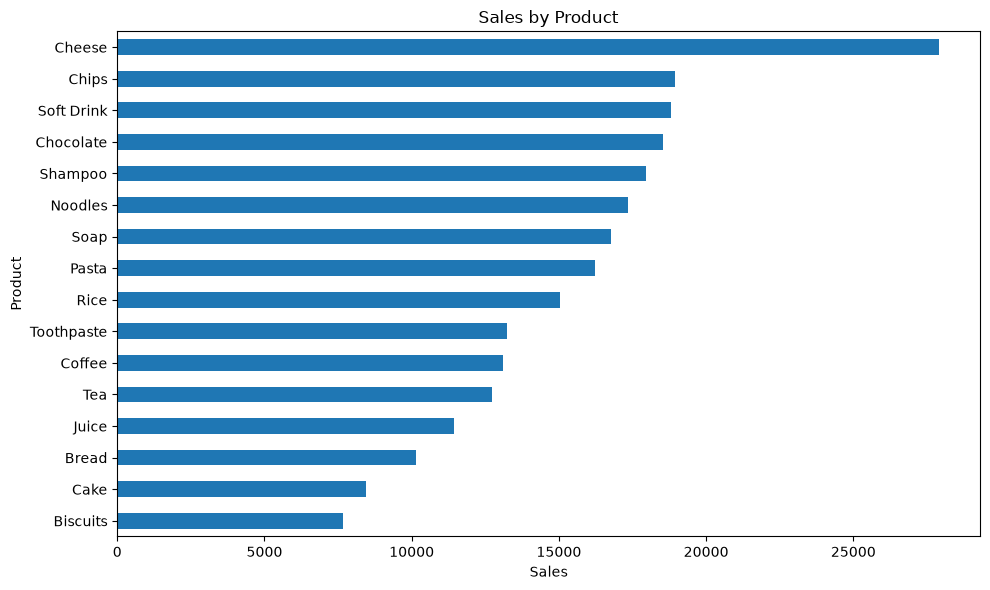

In [19]:
# Product sales visualization

plt.figure(figsize=(10, 6))

product_sales.sort_values().plot(kind="barh")

plt.title("Sales by Product")
plt.xlabel("Sales")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


### Product Insight

Cheese is the highest-selling product, generating Rs. 27,906.30 in
sales. This indicates strong demand for Cheese and suggests that
inventory availability for this product should be maintained.

In [20]:
# Category sales analysis

category_sales = (
    df.groupby("Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print("Sales by Category:")
display(category_sales.to_frame(name="Total Sales"))

highest_category = category_sales.idxmax()
highest_category_sales = category_sales.max()

print(f"\nHighest Sales Category: {highest_category}")
print(f"Sales: Rs. {highest_category_sales:,.2f}")

Sales by Category:


,Total Sales
Category,
Beverages,56108.24
Groceries,48614.33
Personal Care,47956.87
Snacks,37505.33
Dairy,27906.30
Bakery,26264.93



Highest Sales Category: Beverages
Sales: Rs. 56,108.24


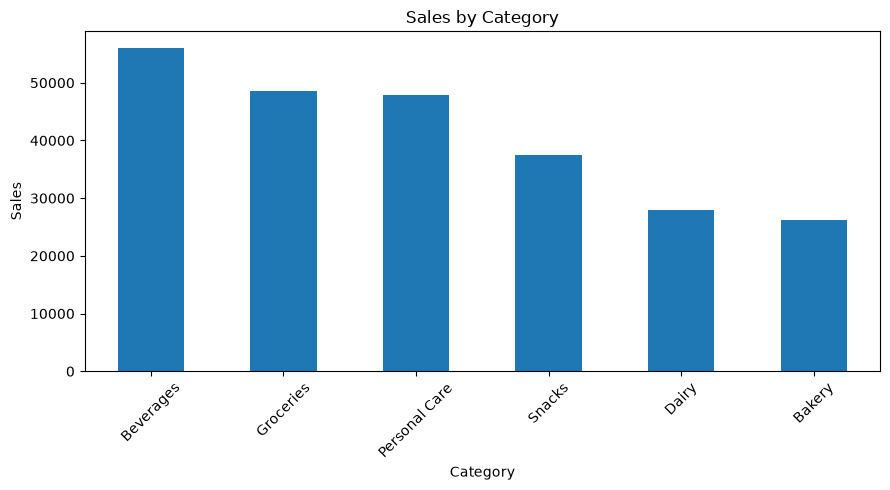

In [21]:
# Category sales visualization

plt.figure(figsize=(9, 5))

category_sales.plot(kind="bar")

plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Category Insight

Beverages is the highest-performing category, generating Rs. 56,108.24
in sales. The supermarket can maintain sufficient inventory and
promotional focus for this category.

In [22]:
# Branch sales analysis

branch_sales = (
    df.groupby(["Branch", "City"])["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print("Sales by Branch:")
display(branch_sales.to_frame(name="Total Sales"))

best_branch = branch_sales.idxmax()
best_branch_sales = branch_sales.max()

print(f"\nBest Performing Branch: {best_branch[0]}")
print(f"City: {best_branch[1]}")
print(f"Sales: Rs. {best_branch_sales:,.2f}")

Sales by Branch:


,,Total Sales
Branch,City,
A,Bangalore,87553.78
B,Delhi,84332.77
C,Mumbai,72469.45



Best Performing Branch: A
City: Bangalore
Sales: Rs. 87,553.78


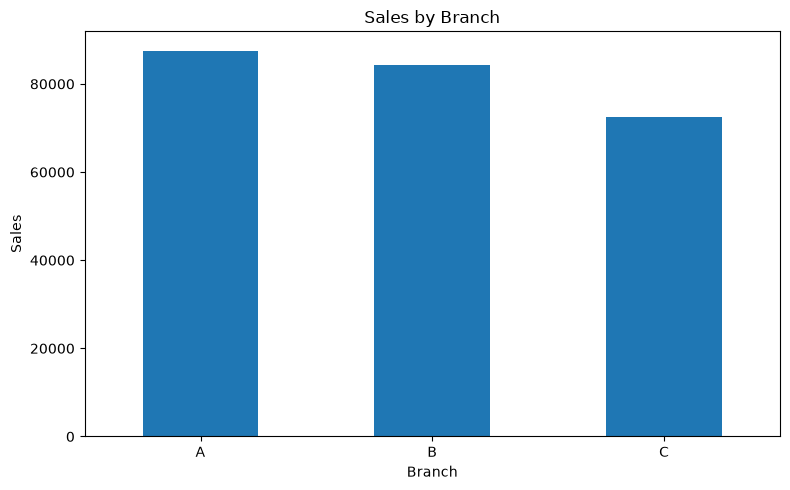

In [23]:
# Branch sales visualization

branch_chart = df.groupby("Branch")["Sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 5))

branch_chart.plot(kind="bar")

plt.title("Sales by Branch")
plt.xlabel("Branch")
plt.ylabel("Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Branch Insight

Branch A in Bangalore is the best-performing branch in the generated
dataset, with sales of Rs. 87,553.78. The performance of this branch
can be studied to identify practices that may be useful for other
branches.

In [24]:
# Payment method analysis

payment_counts = (
    df["Payment Method"]
    .value_counts()
)

print("Transactions by Payment Method:")
display(payment_counts.to_frame(name="Transactions"))

most_used_payment = payment_counts.idxmax()
most_used_payment_count = payment_counts.max()

print(f"\nMost Popular Payment Method: {most_used_payment}")
print(f"Transactions: {most_used_payment_count}")

Transactions by Payment Method:


,Transactions
Payment Method,
Credit Card,187
Debit Card,186
UPI,127



Most Popular Payment Method: Credit Card
Transactions: 187


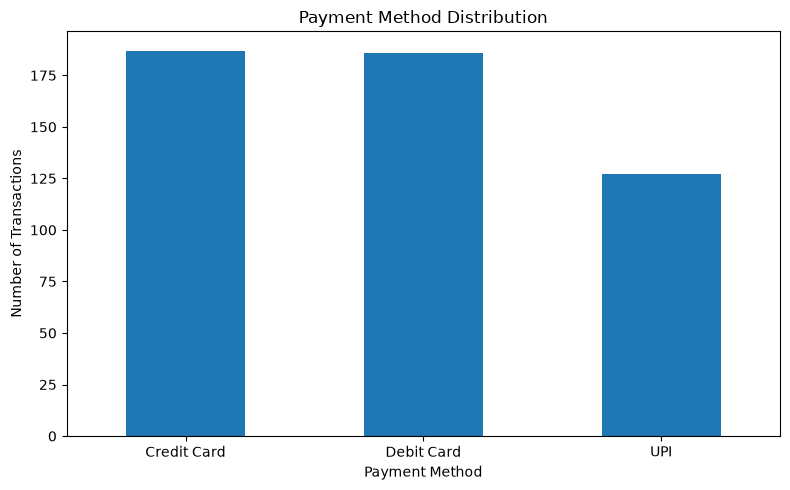

In [25]:
# Payment method visualization

plt.figure(figsize=(8, 5))

payment_counts.plot(kind="bar")

plt.title("Payment Method Distribution")
plt.xlabel("Payment Method")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Payment Method Insight

Credit Card is the most frequently used payment method, with 187
transactions. The supermarket should continue supporting card and
digital payment options for customer convenience.

In [26]:
# Customer type analysis

customer_sales = (
    df.groupby("Customer Type")["Sales"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Sales by Customer Type:")
display(customer_sales.to_frame(name="Average Sales"))

highest_customer_type = customer_sales.idxmax()
highest_customer_average = customer_sales.max()

print(f"\nHigher Average Spending: {highest_customer_type}")
print(f"Average Sales: Rs. {highest_customer_average:,.2f}")

Average Sales by Customer Type:


,Average Sales
Customer Type,
Normal,497.07
Member,483.14



Higher Average Spending: Normal
Average Sales: Rs. 497.07


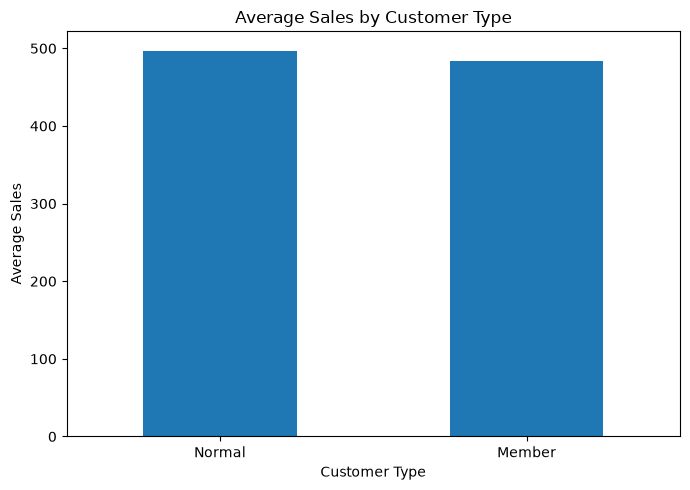

In [27]:
# Customer type visualization

plt.figure(figsize=(7, 5))

customer_sales.plot(kind="bar")

plt.title("Average Sales by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Average Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Customer Type Insight

Normal customers have a higher average transaction value of Rs. 497.07,
compared with Rs. 483.14 for members. This suggests that membership
offers could be reviewed to provide stronger value and encourage higher
spending among members.

In [28]:
# Customer rating analysis

average_rating = df["Rating"].mean()
rating_counts = df["Rating"].value_counts().sort_index()

print("Average Customer Rating:")
print(f"Rating: {average_rating:.2f} / 5")

print("\nRating Distribution:")
display(rating_counts.to_frame(name="Transactions"))

Average Customer Rating:
Rating: 3.99 / 5

Rating Distribution:


,Transactions
Rating,
3.00,252
4.00,1
5.00,247


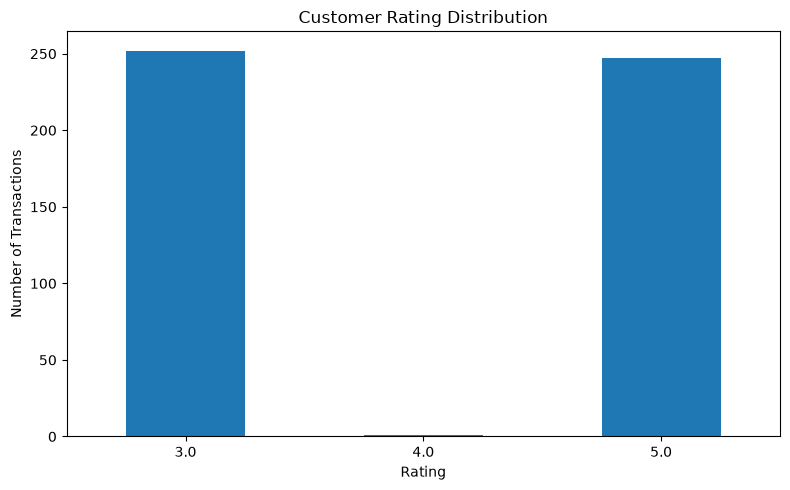

In [29]:
# Customer rating visualization

plt.figure(figsize=(8, 5))

rating_counts.plot(kind="bar")

plt.title("Customer Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Customer Rating Insight

The average customer rating is 3.99 out of 5. Most recorded ratings
are either 3 or 5, with 252 transactions receiving a rating of 3 and
247 transactions receiving a rating of 5. The rating distribution can
be monitored to identify opportunities for improving customer
experience.

# Business Insights and Recommendations

## Key Business Insights

1. **Product Performance:** Cheese is the highest-selling product with
   sales of Rs. 27,906.30.

2. **Category Performance:** Beverages is the highest-selling category
   with sales of Rs. 56,108.24.

3. **Branch Performance:** Branch A in Bangalore is the
   best-performing branch with sales of Rs. 87,553.78.

4. **Payment Preference:** Credit Card is the most frequently used
   payment method with 187 transactions.

5. **Customer Behavior:** Normal customers have a higher average
   transaction value (Rs. 497.07) than members (Rs. 483.14).

6. **Customer Satisfaction:** The average customer rating is 3.99 out
   of 5.

## Business Recommendations

- Maintain sufficient stock of high-performing products such as Cheese.
- Focus on the Beverages category through inventory planning and
  promotional activities.
- Study the performance of Branch A and identify practices that can be
  applied to other branches.
- Continue supporting card and digital payment methods.
- Review membership benefits and offers to encourage higher spending
  among members.
- Monitor customer ratings regularly and use feedback to improve
  customer service.

# Conclusion

This project analyzed 500 supermarket sales transactions using Python,
Pandas, NumPy, Matplotlib, and Seaborn.

The analysis examined product sales, category performance, branch
performance, payment methods, customer types, and customer ratings.

The analysis identified Cheese as the highest-selling product,
Beverages as the highest-selling category, and Branch A in Bangalore
as the best-performing branch in the generated dataset.

The project demonstrates how raw sales data can be transformed into
meaningful business insights that support inventory planning, customer
engagement, payment strategy, and business decision-making.